# RQ1 — Does Adding Agent Skills Change PR Acceptance?

**Research Question.** Does adding AI agent skills (`SKILL.md` files) to a repository change the acceptance rate of pull requests authored by AI coding agents?

**Goal.** Evaluate whether repositories experience a change in AI-authored pull request acceptance after adopting agent skills, compared with repositories that have not yet adopted them.

**Approach.**

1. Identify repositories with reliable skill adoption dates.
2. Construct 30-day observation windows before and after adoption.
3. Select comparable control repositories that have not yet adopted skills.
4. Calculate pull request acceptance rates using observed merge outcomes.
5. Estimate the difference between treated and control repositories.
6. Perform statistical analysis and generate figures.

**Datasets.**
- GitSkills — repository skills and adoption information.
- AIDev v5 — AI-authored pull requests and merge outcomes.

**Observation cutoff.** March 31, 2026.

The analysis builds on the feasibility study and validation scripts developed in the previous phase.

## 0. Configuration

Load the required libraries, locate the project datasets, and verify that the input files are available.


In [1]:

from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RAW = ROOT / "data/raw"
INTERIM = ROOT / "data/interim"
PROCESSED = ROOT / "data/processed"
FIG = ROOT / "figures"

SAMPLE = INTERIM / "phase0_usable_adopters.parquet"
PRS = RAW / "aidev_v5_all_pr.parquet"

for folder in [PROCESSED, FIG]:
    folder.mkdir(parents=True, exist_ok=True)

for path in [SAMPLE, PRS]:
    print(f"{path.name}: {'FOUND' if path.exists() else 'MISSING'}")

con = duckdb.connect()

print("RQ1 configuration completed.")


phase0_usable_adopters.parquet: FOUND
aidev_v5_all_pr.parquet: FOUND
RQ1 configuration completed.


## 1. Define the Study Sample

This section identifies repositories eligible for the RQ1 analysis.

We focus on repositories that:

1. Are included in the AIDev v5 full dataset.
2. Have complete GitSkills adoption-date information.
3. Have at least five AI-authored pull requests before skill adoption.
4. Adopted agent skills early enough to allow 60 days of observation before the AIDev cutoff (March 31, 2026).

We do not require a minimum number of pull requests after adoption to avoid selecting repositories based on post-adoption activity.

The resulting repositories form our initial treated cohort.


In [2]:
CUTOFF = pd.Timestamp("2026-03-31 23:59:59")

treated = con.execute("""
SELECT DISTINCT
    LOWER(repo) AS repo,
    adoption_ts,
    n_pre_adopt,
    n_post_adopt
FROM read_parquet(?)
WHERE scope = 'v5/all'
  AND date_status = 'complete'
  AND n_pre_adopt >= 5
  AND adoption_ts <= TIMESTAMP '2026-03-31 23:59:59'
                     - INTERVAL 60 DAY
""", [str(SAMPLE)]).df()

print("Treated repositories:", len(treated))
print("Unique repositories:", treated["repo"].nunique())
print("Earliest adoption:", treated["adoption_ts"].min())
print("Latest adoption:", treated["adoption_ts"].max())

display(treated.head())


Treated repositories: 424
Unique repositories: 424
Earliest adoption: 2025-10-17 03:42:25
Latest adoption: 2026-01-30 23:13:50


,repo,adoption_ts,n_pre_adopt,n_post_adopt
0,igorganapolsky/random-timer,2026-01-22 15:25:43,9,110
1,bcl1713/chorequest,2025-11-07 14:43:46,33,9
2,graphlessdb/graphlessdb,2025-12-07 16:16:01,38,2
3,tomodo1773/podcast-queue,2026-01-02 12:06:45,39,65
4,rafek1241/ai-copy-paste,2026-01-29 21:19:27,8,0


## 2. Define the Control Group

To evaluate whether agent skills affect pull request acceptance, we need a comparison group.

We select repositories that adopted agent skills after the AIDev v5 observation cutoff (March 31, 2026).

These repositories serve as potential controls because they had not yet adopted skills during our study period.

We apply the same adoption-date completeness and minimum pre-adoption activity requirements used for the treated cohort.

This initial pool will subsequently be matched to treated repositories based on their pre-adoption activity during equivalent calendar periods.


In [3]:
controls = con.execute("""
SELECT DISTINCT
    LOWER(repo) AS repo,
    adoption_ts,
    n_pre_adopt,
    n_post_adopt
FROM read_parquet(?)
WHERE scope = 'v5/all'
  AND date_status = 'complete'
  AND n_pre_adopt >= 5
  AND adoption_ts > TIMESTAMP '2026-03-31 23:59:59'
""", [str(SAMPLE)]).df()

print("Potential control repositories:", len(controls))
print("Unique controls:", controls["repo"].nunique())
print("Earliest control adoption:", controls["adoption_ts"].min())
print("Latest control adoption:", controls["adoption_ts"].max())
print("Overlap with treated:", len(set(treated["repo"]) & set(controls["repo"])))

display(controls.head())


Potential control repositories: 1146
Unique controls: 1146
Earliest control adoption: 2026-04-01 02:28:49
Latest control adoption: 2026-07-20 09:02:15
Overlap with treated: 0


,repo,adoption_ts,n_pre_adopt,n_post_adopt
0,school-of-gaming/sogverse,2026-04-14 09:08:40,10,0
1,revolutionva/757-community-site-public,2026-07-13 13:23:41,16,0
2,lukacf/meerkat-mobkit,2026-06-03 21:53:11,47,0
3,paiml/forjar,2026-06-13 13:37:04,29,0
4,memphis-chains/memphis,2026-05-08 16:59:07,9,0



## 3. Prepare Pull Request Data

This section extracts the AI-authored pull requests associated with the treated and potential control repositories.

We use AIDev v5 and retain pull requests created between September 1, 2025, and March 31, 2026.

For each pull request, we preserve its repository, coding agent, creation date, closure date, and merge date.

These records will be used to construct calendar-aligned observation windows, match control repositories, and measure pull request acceptance.


In [4]:

selected = pd.concat([
    treated[["repo"]].assign(group="treated"),
    controls[["repo"]].assign(group="control")
], ignore_index=True)

con.register("selected_repositories", selected)

con.execute("""
CREATE OR REPLACE TEMP TABLE rq1_prs AS
SELECT
    p.id,
    p.repo,
    p.agent,
    s."group" AS study_group,
    p.created_ts,
    p.closed_ts,
    p.merged_ts
FROM (
    SELECT
        id,
        agent,
        LOWER(REPLACE(
            repo_url,
            'https://api.github.com/repos/',
            ''
        )) AS repo,
        TRY_CAST(REPLACE(created_at, 'Z', '') AS TIMESTAMP) AS created_ts,
        TRY_CAST(REPLACE(closed_at, 'Z', '') AS TIMESTAMP) AS closed_ts,
        TRY_CAST(REPLACE(merged_at, 'Z', '') AS TIMESTAMP) AS merged_ts
    FROM read_parquet(?)
) p
INNER JOIN selected_repositories s
    ON p.repo = s.repo
WHERE p.created_ts >= TIMESTAMP '2025-09-01'
  AND p.created_ts <= TIMESTAMP '2026-03-31 23:59:59'
""", [str(PRS)])

summary = con.execute("""
SELECT
    study_group,
    COUNT(*) AS total_prs,
    COUNT(DISTINCT repo) AS repositories_with_prs,
    COUNT(DISTINCT agent) AS agents,
    MIN(created_ts) AS first_pr,
    MAX(created_ts) AS last_pr
FROM rq1_prs
GROUP BY study_group
ORDER BY study_group
""").df()

display(summary)


,study_group,total_prs,repositories_with_prs,agents,first_pr,last_pr
0,control,45032,1104,6,2025-09-01 01:48:01,2026-03-31 23:58:45
1,treated,26870,413,6,2025-09-01 03:39:06,2026-03-31 23:27:09



## 4. Measure Pre-Adoption Activity

Before matching treated repositories with controls, we measure their activity during the 30 days preceding skill adoption.

For each treated repository, we calculate:

1. The number of AI-authored pull requests created before adoption.
2. The number of distinct AI coding agents active during this period.

These characteristics provide a baseline for identifying comparable control repositories.

Repositories with no pull requests during the pre-adoption window are retained and identified separately, since their acceptance rate cannot be calculated for that period.


In [5]:

con.register("treated_cohort", treated)

treated_pre = con.execute("""
SELECT
    t.repo,
    t.adoption_ts,
    COUNT(p.id) AS pre_30_prs,
    COUNT(DISTINCT p.agent) AS pre_30_agents
FROM treated_cohort t
LEFT JOIN rq1_prs p
    ON p.repo = t.repo
   AND p.created_ts >= t.adoption_ts - INTERVAL 30 DAY
   AND p.created_ts < t.adoption_ts
GROUP BY t.repo, t.adoption_ts
ORDER BY t.repo
""").df()

print("Total treated repositories:", len(treated_pre))

print("With at least 1 pre-adoption PR:",
      (treated_pre["pre_30_prs"] >= 1).sum())

print("With at least 5 pre-adoption PRs:",
      (treated_pre["pre_30_prs"] >= 5).sum())

print("With zero pre-adoption PRs:",
      (treated_pre["pre_30_prs"] == 0).sum())

print("Total pre-adoption PRs:",
      treated_pre["pre_30_prs"].sum())

display(treated_pre.head())


Total treated repositories: 424
With at least 1 pre-adoption PR: 357
With at least 5 pre-adoption PRs: 276
With zero pre-adoption PRs: 67
Total pre-adoption PRs: 7162


,repo,adoption_ts,pre_30_prs,pre_30_agents
0,2389-research/ourocodus,2025-10-28 16:04:51,9,2
1,4eyedengineer/4eyed_development,2025-12-31 20:02:55,53,1
2,4eyedengineer/mcp-everything,2025-12-04 13:55:25,49,1
3,a-tak/bf-copy,2025-11-03 05:05:26,0,0
4,abuklea/prompthub,2025-11-06 09:43:37,6,1



## 5. Measure Control Activity at Matching Dates

Control repositories must be compared with treated repositories over equivalent calendar periods.

For each treated repository, we use its skill adoption date as the reference date and calculate the activity of every potential control during the preceding 30 days.

We measure the number of AI-authored pull requests and the number of distinct coding agents.

This creates a set of candidate treated-control pairs that will be used for matching based on pre-adoption characteristics only.


In [6]:

con.register("treated_pre_cohort", treated_pre)
con.register("control_cohort", controls)

con.execute("""
CREATE OR REPLACE TEMP TABLE control_pre_activity AS
WITH observed AS (
    SELECT
        t.repo AS treated_repo,
        p.repo AS control_repo,
        COUNT(*) AS control_pre_30_prs,
        COUNT(DISTINCT p.agent) AS control_pre_30_agents
    FROM treated_pre_cohort t
    JOIN rq1_prs p
        ON p.study_group = 'control'
       AND p.created_ts >= t.adoption_ts - INTERVAL 30 DAY
       AND p.created_ts < t.adoption_ts
    GROUP BY t.repo, p.repo
)
SELECT
    t.repo AS treated_repo,
    c.repo AS control_repo,
    t.adoption_ts,
    t.pre_30_prs AS treated_pre_30_prs,
    t.pre_30_agents AS treated_pre_30_agents,
    COALESCE(o.control_pre_30_prs, 0) AS control_pre_30_prs,
    COALESCE(o.control_pre_30_agents, 0) AS control_pre_30_agents
FROM treated_pre_cohort t
CROSS JOIN control_cohort c
LEFT JOIN observed o
    ON o.treated_repo = t.repo
   AND o.control_repo = c.repo
""")

control_summary = con.execute("""
SELECT
    COUNT(*) AS candidate_pairs,
    COUNT(DISTINCT treated_repo) AS treated_repositories,
    COUNT(DISTINCT control_repo) AS potential_controls,
    COUNT(*) FILTER (
        WHERE control_pre_30_prs >= 1
    ) AS pairs_with_active_controls,
    COUNT(*) FILTER (
        WHERE treated_pre_30_prs >= 1
          AND control_pre_30_prs >= 1
    ) AS pairs_with_both_active
FROM control_pre_activity
""").df()

display(control_summary)


,candidate_pairs,treated_repositories,potential_controls,pairs_with_active_controls,pairs_with_both_active
0,485904,424,1146,131472,110822



## 6. Match Treated and Control Repositories

We perform one-to-one nearest-neighbor matching without replacement.

Each treated repository is matched to a control repository using two pre-adoption characteristics:

1. The number of AI-authored pull requests in the preceding 30 days.
2. The number of distinct AI coding agents active during that period.

Pull request counts are log-transformed to reduce the influence of highly active repositories.

Matching uses only pre-adoption activity. Post-adoption outcomes are not considered when selecting controls.

A deterministic greedy matching procedure is used. We subsequently examine the quality of the matches before estimating the effect of skill adoption.


In [7]:

candidates = con.execute("""
SELECT
    *,
    ABS(
        LN(1.0 + treated_pre_30_prs)
        - LN(1.0 + control_pre_30_prs)
    )
    + 0.75 * ABS(
        treated_pre_30_agents - control_pre_30_agents
    ) AS match_distance
FROM control_pre_activity
QUALIFY ROW_NUMBER() OVER (
    PARTITION BY treated_repo
    ORDER BY
        ABS(
            LN(1.0 + treated_pre_30_prs)
            - LN(1.0 + control_pre_30_prs)
        )
        + 0.75 * ABS(
            treated_pre_30_agents - control_pre_30_agents
        ),
        control_repo
) <= 300
ORDER BY
    treated_pre_30_prs DESC,
    treated_repo,
    match_distance,
    control_repo
""").df()

used_controls = set()
matches = []

for repo, group in candidates.groupby("treated_repo", sort=False):
    available = group[
        ~group["control_repo"].isin(used_controls)
    ]

    if available.empty:
        continue

    selected = available.iloc[0]
    matches.append(selected)
    used_controls.add(selected["control_repo"])

matched_pairs = pd.DataFrame(matches).reset_index(drop=True)

print("Matched treated repositories:", len(matched_pairs))
print("Unique controls:", matched_pairs["control_repo"].nunique())
print("Unmatched treated repositories:", len(treated) - len(matched_pairs))

print("\nPre-adoption PR activity")
print("Treated average:",
      round(matched_pairs["treated_pre_30_prs"].mean(), 2))
print("Controls average:",
      round(matched_pairs["control_pre_30_prs"].mean(), 2))

print("\nMatching distance")
print(matched_pairs["match_distance"].describe().round(3))

display(matched_pairs.head())


Matched treated repositories: 424
Unique controls: 424
Unmatched treated repositories: 0

Pre-adoption PR activity
Treated average: 16.89
Controls average: 14.79

Matching distance
count    424.000
mean       0.083
std        0.212
min        0.000
25%        0.000
50%        0.000
75%        0.087
max        2.451
Name: match_distance, dtype: float64


,treated_repo,control_repo,adoption_ts,treated_pre_30_prs,treated_pre_30_agents,control_pre_30_prs,control_pre_30_agents,match_distance
0,ops-pivers/lifebalance,nagiyu/nagiyu-platform,2026-01-27 00:24:37,326,3,235,2,1.076128
1,gioe/aiq,bytebase/bytebase,2026-01-05 00:44:49,320,1,226,1,0.346491
2,chippr-robotics/prediction-dao-research,zbigniewsobiecki/llmist,2026-01-16 03:14:32,229,1,159,1,0.362905
3,robinmordasiewicz/terraform-provider-f5xc,dataplat/dbatools,2025-12-04 01:29:26,209,1,66,1,1.142415
4,uspark-hq/uspark,papyszoo/modelibr,2025-10-17 23:19:37,172,1,172,1,0.000000



## 7. Evaluate Matching Quality

Before estimating the effect of skill adoption, we assess whether the matched treated and control repositories have comparable pre-adoption characteristics.

We evaluate:

1. Differences in pull request activity before adoption.
2. Differences in the number of active AI coding agents.
3. Standardized mean differences between the two groups.
4. The distribution of matching distances and potentially poor matches.

Smaller standardized mean differences indicate better balance. Values below 0.1 are commonly used as a reference for acceptable balance, although this does not guarantee that all confounding factors have been addressed.

This step helps assess whether the matched sample is suitable for the subsequent comparison.


In [8]:

def balance_row(name, treated_values, control_values):
    a = np.asarray(treated_values, dtype=float)
    b = np.asarray(control_values, dtype=float)

    pooled_sd = np.sqrt(
        (np.var(a, ddof=1) + np.var(b, ddof=1)) / 2
    )

    smd = (
        (a.mean() - b.mean()) / pooled_sd
        if pooled_sd > 0 else 0.0
    )

    return {
        "measure": name,
        "treated_mean": round(a.mean(), 3),
        "control_mean": round(b.mean(), 3),
        "standardized_difference": round(smd, 3)
    }


balance = pd.DataFrame([
    balance_row(
        "Log(1 + PR count)",
        np.log1p(matched_pairs["treated_pre_30_prs"]),
        np.log1p(matched_pairs["control_pre_30_prs"])
    ),
    balance_row(
        "Number of active agents",
        matched_pairs["treated_pre_30_agents"],
        matched_pairs["control_pre_30_agents"]
    )
])

print("Matching balance:")
display(balance)

print("Exact matches:",
      (matched_pairs["match_distance"] == 0).sum())

print("Matches with distance > 0.5:",
      (matched_pairs["match_distance"] > 0.5).sum())

print("Matches with distance > 1:",
      (matched_pairs["match_distance"] > 1).sum())

print("\nFive worst matches:")
display(
    matched_pairs.nlargest(
        5, "match_distance"
    )[[
        "treated_repo",
        "control_repo",
        "treated_pre_30_prs",
        "control_pre_30_prs",
        "treated_pre_30_agents",
        "control_pre_30_agents",
        "match_distance"
    ]]
)


Matching balance:


,measure,treated_mean,control_mean,standardized_difference
0,Log(1 + PR count),2.034,1.987,0.037
1,Number of active agents,1.019,0.993,0.043


Exact matches: 262
Matches with distance > 0.5: 16
Matches with distance > 1: 8

Five worst matches:


,treated_repo,control_repo,treated_pre_30_prs,control_pre_30_prs,treated_pre_30_agents,control_pre_30_agents,match_distance
171,topstolenname/agisa_sac,sidprasad/spytial-core,10,8,5,2,2.450671
12,neongreen/mono,nikolaymetchev/money-manager,88,50,3,2,1.306811
3,robinmordasiewicz/terraform-provider-f5xc,dataplat/dbatools,209,66,1,1,1.142415
112,jamesprial/go-reddit-api-wrapper,actualbudget/actual,16,11,3,2,1.098307
0,ops-pivers/lifebalance,nagiyu/nagiyu-platform,326,235,3,2,1.076128



## 8. Construct Matched Observation Windows

We construct four observation windows for each matched pair:

1. Treated repository — 30 days before skill adoption.
2. Treated repository — 30 days after skill adoption.
3. Control repository — the same 30-day pre-adoption period.
4. Control repository — the same 30-day post-adoption period.

The control repository uses the adoption date of its matched treated repository as a reference date.

For each window, we identify pull requests that were merged, closed without merging, or unresolved within 30 days of creation.

This produces the data needed to compare acceptance rates across treated and control repositories.


In [9]:

pairs = matched_pairs.reset_index(drop=True).copy()
pairs["pair_id"] = np.arange(1, len(pairs) + 1)

frames = []

for group, repo_column in [
    ("treated", "treated_repo"),
    ("control", "control_repo")
]:
    for period in ["before", "after"]:
        frame = pairs[
            ["pair_id", "adoption_ts", repo_column]
        ].rename(columns={repo_column: "repo"}).copy()

        frame["study_group"] = group
        frame["period"] = period

        if period == "before":
            frame["window_start"] = (
                frame["adoption_ts"] - pd.Timedelta(days=30)
            )
            frame["window_end"] = frame["adoption_ts"]
        else:
            frame["window_start"] = frame["adoption_ts"]
            frame["window_end"] = (
                frame["adoption_ts"] + pd.Timedelta(days=30)
            )

        frames.append(frame)

windows = pd.concat(frames, ignore_index=True)

con.register("rq1_windows", windows)

con.execute("""
CREATE OR REPLACE TEMP TABLE rq1_window_prs AS
SELECT
    w.pair_id,
    w.study_group,
    w.period,
    w.repo,
    w.adoption_ts,
    p.id,
    p.agent,
    p.created_ts,
    p.closed_ts,
    p.merged_ts,
    CASE
        WHEN p.id IS NULL THEN NULL
        WHEN p.merged_ts >= p.created_ts
         AND p.merged_ts < p.created_ts + INTERVAL 30 DAY
            THEN 'merged_30d'
        WHEN p.merged_ts IS NULL
         AND p.closed_ts >= p.created_ts
         AND p.closed_ts < p.created_ts + INTERVAL 30 DAY
            THEN 'closed_unmerged_30d'
        ELSE 'unresolved_30d'
    END AS outcome_30d
FROM rq1_windows w
LEFT JOIN rq1_prs p
    ON p.repo = w.repo
   AND p.created_ts >= w.window_start
   AND p.created_ts < w.window_end
""")

window_summary = con.execute("""
SELECT
    study_group,
    period,
    COUNT(DISTINCT pair_id) AS pairs,
    COUNT(DISTINCT pair_id) FILTER (
        WHERE id IS NOT NULL
    ) AS active_pairs,
    COUNT(id) AS total_prs,
    COUNT(id) FILTER (
        WHERE outcome_30d = 'merged_30d'
    ) AS merged_30d,
    COUNT(id) FILTER (
        WHERE outcome_30d = 'closed_unmerged_30d'
    ) AS closed_unmerged_30d,
    COUNT(id) FILTER (
        WHERE outcome_30d = 'unresolved_30d'
    ) AS unresolved_30d
FROM rq1_window_prs
GROUP BY study_group, period
ORDER BY
    study_group,
    CASE period WHEN 'before' THEN 0 ELSE 1 END
""").df()

display(window_summary)

assert (
    window_summary["total_prs"]
    == window_summary["merged_30d"]
    + window_summary["closed_unmerged_30d"]
    + window_summary["unresolved_30d"]
).all()

print("Matched observation windows validated.")


,study_group,period,pairs,active_pairs,total_prs,merged_30d,closed_unmerged_30d,unresolved_30d
0,control,before,424,357,6270,5034,853,383
1,control,after,424,233,5852,5128,571,153
2,treated,before,424,357,7162,6504,559,99
3,treated,after,424,317,7371,6744,475,152


Matched observation windows validated.



## 9. Calculate PR Acceptance Rates

We measure pull request acceptance using the proportion of AI-authored pull requests merged within 30 days of creation.

**30-day Merge Rate = PRs merged within 30 days / Total PRs created**

Pull requests that remain unresolved or are merged after 30 days are not counted as successful merges within the observation window.

We calculate this metric for treated and control repositories, before and after the reference adoption date.

We then compute a preliminary difference-in-differences (DiD) estimate by subtracting the change observed in control repositories from the change observed in treated repositories.

These initial rates are pooled across pull requests. A subsequent paired repository-level analysis will assess statistical uncertainty and account for differences between repositories.


In [10]:

acceptance = window_summary.copy()

acceptance["merge_rate_30d"] = (
    100 * acceptance["merged_30d"]
    / acceptance["total_prs"]
)

display(
    acceptance[[
        "study_group",
        "period",
        "total_prs",
        "merged_30d",
        "merge_rate_30d"
    ]].round(2)
)

rates = acceptance.set_index(
    ["study_group", "period"]
)["merge_rate_30d"]

treated_change = (
    rates.loc[("treated", "after")]
    - rates.loc[("treated", "before")]
)

control_change = (
    rates.loc[("control", "after")]
    - rates.loc[("control", "before")]
)

did = treated_change - control_change

print("Treated change:", round(treated_change, 2), "percentage points")
print("Control change:", round(control_change, 2), "percentage points")
print("Preliminary DiD:", round(did, 2), "percentage points")


,study_group,period,total_prs,merged_30d,merge_rate_30d
0,control,before,6270,5034,80.29
1,control,after,5852,5128,87.63
2,treated,before,7162,6504,90.81
3,treated,after,7371,6744,91.49


Treated change: 0.68 percentage points
Control change: 7.34 percentage points
Preliminary DiD: -6.66 percentage points



## 10. Repository-Level Acceptance Rates

The previous analysis pooled all pull requests, giving greater weight to repositories with high PR activity.

We now calculate the 30-day merge rate separately for each repository and observation period.

We also identify matched pairs with at least one pull request in all four observation windows.

Repositories without pull requests have an undefined acceptance rate rather than a rate of zero.

This step establishes the coverage of the paired analysis and identifies potential selection bias before statistical testing.


In [11]:

repo_rates = con.execute("""
SELECT
    pair_id,
    study_group,
    period,
    COUNT(id) AS n_prs,
    COUNT(id) FILTER (
        WHERE outcome_30d = 'merged_30d'
    ) AS n_merged
FROM rq1_window_prs
GROUP BY pair_id, study_group, period
ORDER BY pair_id, study_group, period
""").df()

repo_rates["merge_rate"] = (
    repo_rates["n_merged"]
    / repo_rates["n_prs"].replace(0, np.nan)
)

coverage = repo_rates.pivot(
    index="pair_id",
    columns=["study_group", "period"],
    values="n_prs"
)

required = [
    ("treated", "before"),
    ("treated", "after"),
    ("control", "before"),
    ("control", "after")
]

complete_pairs = coverage[required].gt(0).all(axis=1)

print("Total matched pairs:", len(coverage))

print("Pairs with PRs in all four windows:",
      complete_pairs.sum())

print("Pairs missing at least one active window:",
      (~complete_pairs).sum())

print("\nActive repositories by group and period:")

activity = repo_rates.groupby(
    ["study_group", "period"]
).agg(
    active_repositories=("n_prs", lambda x: (x > 0).sum()),
    average_prs=("n_prs", "mean")
).reset_index()

display(activity.round(2))

print("\nRepository-level merge rates:")

repository_summary = repo_rates.groupby(
    ["study_group", "period"]
).agg(
    repositories_with_rate=("merge_rate", "count"),
    mean_merge_rate=("merge_rate", "mean"),
    median_merge_rate=("merge_rate", "median")
).reset_index()

repository_summary["mean_merge_rate"] *= 100
repository_summary["median_merge_rate"] *= 100

display(repository_summary.round(2))


Total matched pairs: 424
Pairs with PRs in all four windows: 184
Pairs missing at least one active window: 240

Active repositories by group and period:


,study_group,period,active_repositories,average_prs
0,control,after,233,13.80
1,control,before,357,14.79
2,treated,after,317,17.38
3,treated,before,357,16.89



Repository-level merge rates:


,study_group,period,repositories_with_rate,mean_merge_rate,median_merge_rate
0,control,after,233,72.62,89.29
1,control,before,357,73.85,85.56
2,treated,after,317,85.40,96.72
3,treated,before,357,86.58,97.47



## 11. Paired Difference-in-Differences Analysis

We estimate the difference-in-differences (DiD) in 30-day pull request merge rates using matched repository pairs.

For each pair, we calculate the change in acceptance rate before and after the treated repository's skill adoption date. We then subtract the corresponding change observed in its matched control repository.

**DiD = (Treated After − Treated Before) − (Control After − Control Before)**

Each matched pair receives equal weight.

The analysis is restricted to pairs with at least one pull request in all four observation windows, because acceptance rates are undefined when no pull requests exist.

We use paired bootstrap resampling to estimate a 95% confidence interval. This complete-case analysis is exploratory, as requiring post-adoption activity may introduce selection bias.


In [12]:

wide_rates = repo_rates.pivot(
    index="pair_id",
    columns=["study_group", "period"],
    values="merge_rate"
)

paired = wide_rates[required].dropna().copy()

paired.columns = [
    "treated_before",
    "treated_after",
    "control_before",
    "control_after"
]

paired["treated_change"] = (
    paired["treated_after"] - paired["treated_before"]
)

paired["control_change"] = (
    paired["control_after"] - paired["control_before"]
)

paired["did"] = (
    paired["treated_change"] - paired["control_change"]
)

print("Complete matched pairs:", len(paired))

results = pd.DataFrame([
    {
        "group": group,
        "before_pct": paired[f"{group}_before"].mean() * 100,
        "after_pct": paired[f"{group}_after"].mean() * 100,
        "change_pp": paired[f"{group}_change"].mean() * 100
    }
    for group in ["treated", "control"]
])

display(results.round(2))

estimate = paired["did"].mean()

rng = np.random.default_rng(2027)
values = paired["did"].to_numpy()

B = 5000

boot_means = np.array([
    rng.choice(values, size=len(values), replace=True).mean()
    for _ in range(B)
])

ci_low, ci_high = np.quantile(
    boot_means, [0.025, 0.975]
)

print("Paired DiD:", round(estimate * 100, 2), "percentage points")
print(
    "95% bootstrap CI:",
    round(ci_low * 100, 2),
    "to",
    round(ci_high * 100, 2),
    "percentage points"
)


Complete matched pairs: 184


,group,before_pct,after_pct,change_pp
0,treated,87.59,82.83,-4.77
1,control,73.29,73.40,0.11


Paired DiD: -4.88 percentage points
95% bootstrap CI: -10.95 to 1.05 percentage points



## 12. Verify Outcome Censoring

The AIDev v5 observation cutoff is March 31, 2026.

To avoid using future information, we verify whether any pull requests were merged or closed after this cutoff.

We compare the original 30-day outcomes with outcomes observable by the cutoff date.

This check ensures that the analysis does not incorrectly use decisions recorded after the observation period.


In [13]:

cutoff_audit = con.execute("""
WITH checked AS (
    SELECT
        study_group,
        period,
        id,
        outcome_30d,
        CASE
            WHEN id IS NULL THEN NULL
            WHEN merged_ts >= created_ts
             AND merged_ts < created_ts + INTERVAL 30 DAY
             AND merged_ts <= TIMESTAMP '2026-03-31 23:59:59'
                THEN 'merged_30d'
            WHEN merged_ts IS NULL
             AND closed_ts >= created_ts
             AND closed_ts < created_ts + INTERVAL 30 DAY
             AND closed_ts <= TIMESTAMP '2026-03-31 23:59:59'
                THEN 'closed_unmerged_30d'
            ELSE 'unresolved_30d'
        END AS corrected_outcome
    FROM rq1_window_prs
)
SELECT
    study_group,
    period,
    COUNT(id) AS total_prs,
    COUNT(id) FILTER (
        WHERE outcome_30d <> corrected_outcome
    ) AS changed_outcomes,
    COUNT(id) FILTER (
        WHERE corrected_outcome = 'merged_30d'
    ) AS corrected_merged,
    COUNT(id) FILTER (
        WHERE corrected_outcome = 'closed_unmerged_30d'
    ) AS corrected_closed,
    COUNT(id) FILTER (
        WHERE corrected_outcome = 'unresolved_30d'
    ) AS corrected_unresolved
FROM checked
GROUP BY study_group, period
ORDER BY study_group, period
""").df()

display(cutoff_audit)
print("Total outcomes affected:",
      cutoff_audit["changed_outcomes"].sum())


,study_group,period,total_prs,changed_outcomes,corrected_merged,corrected_closed,corrected_unresolved
0,control,after,5852,0,5128,571,153
1,control,before,6270,0,5034,853,383
2,treated,after,7371,0,6744,475,152
3,treated,before,7162,0,6504,559,99


Total outcomes affected: 0



## 13. Sensitivity Analysis

We assess the robustness of the paired difference-in-differences estimate under stricter sample requirements.

Three alternative samples are examined:

1. Well-matched pairs with a matching distance no greater than 0.5.
2. Pairs with at least five pull requests in each observation window.
3. Pairs satisfying both conditions.

For each sample, we recompute the average difference-in-differences estimate and its 95% bootstrap confidence interval.

This analysis examines whether the findings are sensitive to matching quality and small sample sizes within individual repositories.

These restrictions do not eliminate potential selection bias or establish causality.


In [14]:

sensitivity_data = paired[["did"]].copy()

sensitivity_data["match_distance"] = (
    pairs.set_index("pair_id")
    .loc[sensitivity_data.index, "match_distance"]
)

sensitivity_data["min_window_prs"] = (
    coverage.loc[sensitivity_data.index, required]
    .min(axis=1)
)

samples = {
    "Main analysis": sensitivity_data,
    "Match distance <= 0.5": sensitivity_data[
        sensitivity_data["match_distance"] <= 0.5
    ],
    "At least 5 PRs per window": sensitivity_data[
        sensitivity_data["min_window_prs"] >= 5
    ],
    "Both restrictions": sensitivity_data[
        (sensitivity_data["match_distance"] <= 0.5)
        & (sensitivity_data["min_window_prs"] >= 5)
    ]
}

rng = np.random.default_rng(2027)
sensitivity_results = []

for name, sample in samples.items():
    values = sample["did"].to_numpy()
    n = len(values)

    if n < 2:
        sensitivity_results.append({
            "sample": name,
            "pairs": n,
            "did_pp": np.nan,
            "ci_lower_pp": np.nan,
            "ci_upper_pp": np.nan
        })
        continue

    bootstrap = np.array([
        rng.choice(values, size=n, replace=True).mean()
        for _ in range(5000)
    ])

    lower, upper = np.quantile(
        bootstrap, [0.025, 0.975]
    )

    sensitivity_results.append({
        "sample": name,
        "pairs": n,
        "did_pp": values.mean() * 100,
        "ci_lower_pp": lower * 100,
        "ci_upper_pp": upper * 100
    })

sensitivity_results = pd.DataFrame(sensitivity_results)

display(sensitivity_results.round(2))


,sample,pairs,did_pp,ci_lower_pp,ci_upper_pp
0,Main analysis,184,-4.88,-10.95,1.05
1,Match distance <= 0.5,176,-5.11,-11.44,1.35
2,At least 5 PRs per window,80,-1.19,-6.18,3.85
3,Both restrictions,75,-1.10,-6.16,4.05



## 14. Assess Sample Selection

The paired difference-in-differences analysis includes only repositories with at least one pull request in all four observation windows.

This requirement reduces the matched sample from 424 to 184 pairs.

To assess possible selection bias, we compare included and excluded pairs using their pre-adoption characteristics:

1. Pull request activity.
2. Number of active AI coding agents.
3. Matching quality.
4. Pre-adoption merge rates.

Differences between these groups may limit the generalizability of the complete-case analysis.


In [15]:

selection_data = pairs[[
    "pair_id",
    "match_distance",
    "treated_pre_30_prs",
    "control_pre_30_prs",
    "treated_pre_30_agents",
    "control_pre_30_agents"
]].copy()

selection_data["sample"] = np.where(
    selection_data["pair_id"].isin(paired.index),
    "Included",
    "Excluded"
)

pre_rates = repo_rates[
    repo_rates["period"] == "before"
].pivot(
    index="pair_id",
    columns="study_group",
    values="merge_rate"
).rename(columns={
    "treated": "treated_pre_rate",
    "control": "control_pre_rate"
}).reset_index()

selection_data = selection_data.merge(
    pre_rates,
    on="pair_id",
    how="left",
    validate="one_to_one"
)

selection_summary = selection_data.groupby(
    "sample"
).agg(
    pairs=("pair_id", "count"),
    treated_pre_prs=("treated_pre_30_prs", "mean"),
    control_pre_prs=("control_pre_30_prs", "mean"),
    treated_agents=("treated_pre_30_agents", "mean"),
    control_agents=("control_pre_30_agents", "mean"),
    match_distance=("match_distance", "mean"),
    treated_pre_rate=("treated_pre_rate", "mean"),
    control_pre_rate=("control_pre_rate", "mean")
).reset_index()

selection_summary["treated_pre_rate"] *= 100
selection_summary["control_pre_rate"] *= 100

display(selection_summary.round(2))

print("Total pairs:", len(selection_data))
print("Included pairs:", len(paired))
print("Excluded pairs:", len(selection_data) - len(paired))
print("Sample retention:", round(100 * len(paired) / len(selection_data), 2), "%")


,sample,pairs,treated_pre_prs,control_pre_prs,treated_agents,control_agents,match_distance,treated_pre_rate,control_pre_rate
0,Excluded,240,8.48,7.88,0.88,0.85,0.07,85.51,74.45
1,Included,184,27.86,23.80,1.20,1.17,0.10,87.59,73.29


Total pairs: 424
Included pairs: 184
Excluded pairs: 240
Sample retention: 43.4 %



## 15. Visualize RQ1 Results

This section generates two figures to summarize the RQ1 findings.

**Figure 1 — Pull Request Acceptance Before and After Adoption**

We compare the mean 30-day merge rates of treated and control repositories before and after skill adoption. The comparison uses the 184 matched pairs with pull requests in all four observation windows.

**Figure 2 — Sensitivity Analysis**

We visualize the difference-in-differences estimates and their 95% bootstrap confidence intervals across the four sensitivity-analysis samples.

These figures illustrate the observed differences and their uncertainty. The results are exploratory because the complete-case sample may be affected by selection bias, and matching does not eliminate all potential confounding factors.


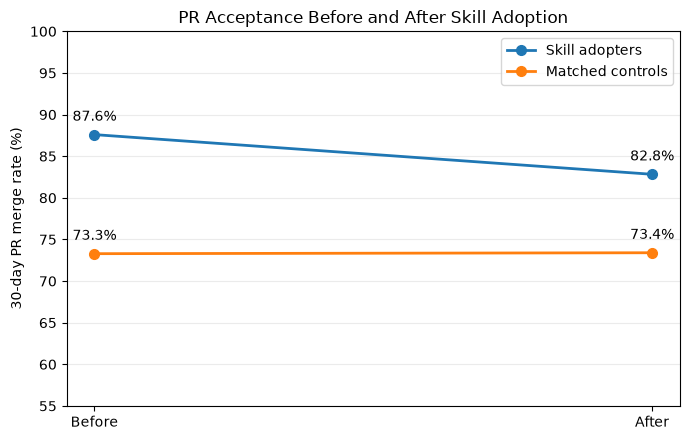

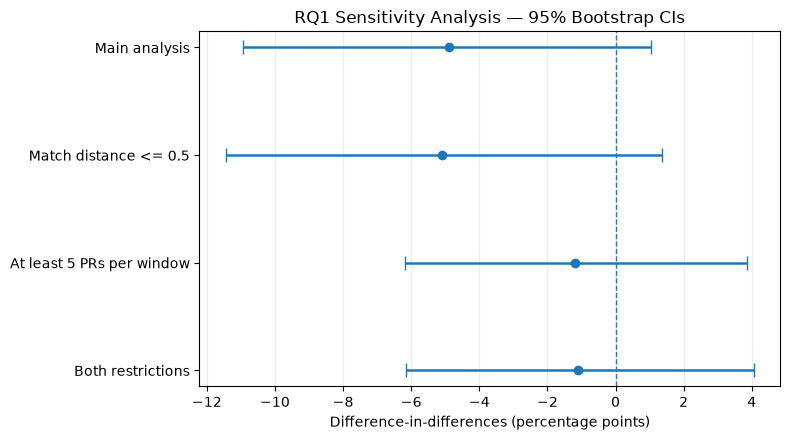

Figures saved:
/Users/raselchowdhury/Desktop/Untitled/figures/rq1_merge_rates.png
/Users/raselchowdhury/Desktop/Untitled/figures/rq1_sensitivity.png


In [16]:

FIG.mkdir(parents=True, exist_ok=True)

x = np.array([0, 1])

fig, ax = plt.subplots(figsize=(7, 4.5))

for group, label in [
    ("treated", "Skill adopters"),
    ("control", "Matched controls")
]:
    values = [
        paired[f"{group}_before"].mean() * 100,
        paired[f"{group}_after"].mean() * 100
    ]

    ax.plot(x, values, marker="o", linewidth=2, markersize=7, label=label)

    for xi, yi in zip(x, values):
        ax.annotate(
            f"{yi:.1f}%",
            (xi, yi),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center"
        )

ax.set_xticks(x, ["Before", "After"])
ax.set_ylabel("30-day PR merge rate (%)")
ax.set_title("PR Acceptance Before and After Skill Adoption")
ax.set_ylim(55, 100)
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(FIG / "rq1_merge_rates.png", dpi=300, bbox_inches="tight")
plt.show()

sens = sensitivity_results.copy()
y = np.arange(len(sens))

estimates = sens["did_pp"].to_numpy()
lower = sens["ci_lower_pp"].to_numpy()
upper = sens["ci_upper_pp"].to_numpy()

errors = np.vstack([
    estimates - lower,
    upper - estimates
])

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.errorbar(
    estimates,
    y,
    xerr=errors,
    fmt="o",
    capsize=5,
    markersize=6,
    linewidth=1.8
)

ax.axvline(0, linestyle="--", linewidth=1)
ax.set_yticks(y, sens["sample"])
ax.invert_yaxis()

ax.set_xlabel("Difference-in-differences (percentage points)")
ax.set_title("RQ1 Sensitivity Analysis — 95% Bootstrap CIs")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
fig.savefig(FIG / "rq1_sensitivity.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figures saved:")
print(FIG / "rq1_merge_rates.png")
print(FIG / "rq1_sensitivity.png")



## 16. Export RQ1 Results

This section exports the final RQ1 analysis outputs to support reproducibility and preparation of the research report.

We save:

1. The matched treated-control repository pairs.
2. The pull request outcomes across observation windows.
3. The repository-level paired difference-in-differences estimates.
4. The sensitivity analysis results.
5. The sample selection assessment.
6. A summary of the main statistical findings.

All results are derived from the observed GitSkills and AIDev data. The complete-case estimates remain exploratory and should not be interpreted as causal evidence.


In [17]:

PROCESSED.mkdir(parents=True, exist_ok=True)

outputs = {
    "rq1_matched_pairs.csv": pairs,
    "rq1_window_summary.csv": window_summary,
    "rq1_paired_results.csv": paired.reset_index(),
    "rq1_sensitivity.csv": sensitivity_results,
    "rq1_selection_summary.csv": selection_summary
}

for filename, dataframe in outputs.items():
    path = PROCESSED / filename
    dataframe.to_csv(path, index=False)
    print("Saved:", filename, "| Rows:", len(dataframe))

summary_text = f"""
RQ1 — Does Adding Agent Skills Change PR Acceptance?

Treated repositories: {len(treated)}
Potential control repositories: {len(controls)}
Matched repository pairs: {len(pairs)}
Complete pairs used in the paired analysis: {len(paired)}
Sample retention: {100 * len(paired) / len(pairs):.2f}%

Main paired difference-in-differences:
Estimate: {estimate * 100:.2f} percentage points
95% bootstrap confidence interval:
[{ci_low * 100:.2f}, {ci_high * 100:.2f}] percentage points

Interpretation:
The estimated difference is negative, but the confidence interval
includes zero. The analysis does not establish a statistically
conclusive change in PR acceptance following skill adoption.

Limitations:
- Complete-case selection depends on post-adoption PR activity.
- Matching does not eliminate unobserved confounding.
- Skill adoption dates are inferred from GitSkills history.
- Repositories with no PRs have undefined acceptance rates.
- The comparison does not establish causality.
"""

summary_path = PROCESSED / "rq1_results_summary.txt"
summary_path.write_text(summary_text.strip(), encoding="utf-8")

print("\nSaved:", summary_path.name)
print("\nRQ1 results exported successfully.")


Saved: rq1_matched_pairs.csv | Rows: 424
Saved: rq1_window_summary.csv | Rows: 4
Saved: rq1_paired_results.csv | Rows: 184
Saved: rq1_sensitivity.csv | Rows: 4
Saved: rq1_selection_summary.csv | Rows: 2

Saved: rq1_results_summary.txt

RQ1 results exported successfully.



## 17. Conclusion and Threats to Validity

### RQ1 — Does Adding Agent Skills Change PR Acceptance?

Our study examined whether the adoption of `SKILL.md` files is associated with changes in the acceptance rates of AI-authored pull requests.

We identified 424 eligible adopting repositories and matched them with 424 control repositories based on pre-adoption PR activity and the number of active AI coding agents.

The main paired analysis included 184 repository pairs with at least one PR in all four observation windows.

### Main Findings

The mean 30-day merge rate among adopting repositories decreased from 87.59% before adoption to 82.83% after adoption.

For matched controls, the corresponding rate increased slightly from 73.29% to 73.40%.

The paired difference-in-differences estimate was **−4.88 percentage points**, with a 95% bootstrap confidence interval of **[−10.95, +1.05]**.

Because the confidence interval includes zero, the evidence does not establish a statistically conclusive association between skill adoption and changes in PR acceptance.

### Sensitivity Analysis

Restricting the analysis to better-matched repositories produced a similar estimate of −5.11 percentage points.

However, requiring at least five PRs per observation window reduced the estimated difference to −1.19 percentage points.

All examined confidence intervals included zero.

### Threats to Validity

- **Selection bias:** Only 184 of 424 matched pairs had PRs in all four observation windows. These repositories were more active before adoption than excluded repositories.
- **Unobserved confounding:** Matching accounts for PR volume and agent diversity, but other repository characteristics may influence acceptance.
- **Adoption-date uncertainty:** GitSkills adoption dates are inferred from observed `SKILL.md` commit histories and may not represent the first historical adoption.
- **Outcome measurement:** We measure merging within 30 days, which may differ from eventual PR acceptance.
- **Temporal effects:** Calendar-aligned controls reduce some time-related differences, but parallel pre-adoption trends have not been established.

### Answer to RQ1

The observed results suggest a possible negative association between skill adoption and subsequent AI-authored PR acceptance. However, this association is not statistically conclusive and is sensitive to sample restrictions.

Therefore, **we cannot conclude that adding agent skills increases or decreases PR acceptance based on the available evidence**.


In [18]:

expected_files = [
    PROCESSED / "rq1_matched_pairs.csv",
    PROCESSED / "rq1_window_summary.csv",
    PROCESSED / "rq1_paired_results.csv",
    PROCESSED / "rq1_sensitivity.csv",
    PROCESSED / "rq1_selection_summary.csv",
    PROCESSED / "rq1_results_summary.txt",
    FIG / "rq1_merge_rates.png",
    FIG / "rq1_sensitivity.png"
]

for path in expected_files:
    assert path.exists(), f"Missing output: {path.name}"

assert len(pairs) == 424
assert len(paired) == 184
assert ci_low <= 0 <= ci_high

print("RQ1 final verification: PASSED")
print("Output files verified:", len(expected_files))
print("Matched pairs:", len(pairs))
print("Complete pairs:", len(paired))
print(f"Paired DiD: {estimate * 100:.2f} percentage points")
print(f"95% CI: [{ci_low * 100:.2f}, {ci_high * 100:.2f}]")
print("Conclusion: No statistically conclusive effect established.")


RQ1 final verification: PASSED
Output files verified: 8
Matched pairs: 424
Complete pairs: 184
Paired DiD: -4.88 percentage points
95% CI: [-10.95, 1.05]
Conclusion: No statistically conclusive effect established.


## 18. Examine Pre-Adoption Trends

This section examines whether treated and matched control repositories followed similar PR acceptance trends before skill adoption.

We divide the 30-day pre-adoption observation window into two consecutive 15-day periods.

For each repository pair, we compare changes in the 30-day PR merge rate across these periods.

This diagnostic helps assess the plausibility of the parallel trends assumption underlying difference-in-differences.

**Limitations.** The analysis is restricted to repositories with observed PRs in both pre-adoption periods. Two short intervals cannot establish parallel trends, and smaller samples may produce imprecise estimates.

In [28]:
pretrend_data = con.execute("""
SELECT
    pair_id,
    study_group,
    CASE
        WHEN created_ts < adoption_ts - INTERVAL 15 DAY
            THEN 'Early'
        ELSE 'Late'
    END AS pre_period,
    COUNT(id) AS prs,
    COUNT(id) FILTER (
        WHERE outcome_30d = 'merged_30d'
    ) AS merged
FROM rq1_window_prs
WHERE period = 'before'
  AND id IS NOT NULL
GROUP BY 1, 2, 3
""").df()

pretrend_data["merge_rate"] = (
    pretrend_data["merged"] / pretrend_data["prs"]
)

columns = pd.MultiIndex.from_tuples([
    ("treated", "Early"),
    ("treated", "Late"),
    ("control", "Early"),
    ("control", "Late")
])

pretrend_wide = pretrend_data.pivot(
    index="pair_id",
    columns=["study_group", "pre_period"],
    values="merge_rate"
)

pretrend_pairs = pretrend_wide.reindex(
    index=paired.index,
    columns=columns
).dropna().copy()

print("Main analysis pairs:", len(paired))
print("Pairs with all four pre-period observations:", len(pretrend_pairs))

if len(pretrend_pairs) >= 2:
    treated_change = (
        pretrend_pairs[("treated", "Late")]
        - pretrend_pairs[("treated", "Early")]
    )

    control_change = (
        pretrend_pairs[("control", "Late")]
        - pretrend_pairs[("control", "Early")]
    )

    pretrend_difference = (
        treated_change - control_change
    ).to_numpy()

    rng = np.random.default_rng(2027)

    bootstrap = rng.choice(
        pretrend_difference,
        size=(5000, len(pretrend_difference)),
        replace=True
    ).mean(axis=1)

    lower, upper = np.percentile(
        bootstrap, [2.5, 97.5]
    )

    print("\nTreated pre-adoption change:",
          round(treated_change.mean() * 100, 2), "pp")

    print("Control pre-adoption change:",
          round(control_change.mean() * 100, 2), "pp")

    print("Difference in pre-adoption trends:",
          round(pretrend_difference.mean() * 100, 2), "pp")

    print("95% bootstrap CI:",
          round(lower * 100, 2),
          "to",
          round(upper * 100, 2), "pp")

    print("Confidence interval includes zero:",
          bool(lower <= 0 <= upper))
else:
    print("Insufficient observations for pre-trend assessment.")

print("\nPre-adoption trend diagnostic completed.")

Main analysis pairs: 184
Pairs with all four pre-period observations: 51

Treated pre-adoption change: -1.77 pp
Control pre-adoption change: -2.01 pp
Difference in pre-adoption trends: 0.24 pp
95% bootstrap CI: -8.24 to 8.48 pp
Confidence interval includes zero: True

Pre-adoption trend diagnostic completed.


In [29]:
pretrend_ids = pd.DataFrame({
    "pair_id": pretrend_pairs.index.to_numpy()
})

con.register("rq1_pretrend_check_pairs", pretrend_ids)

pretrend_timing_audit = con.execute("""
SELECT
    w.study_group,
    CASE
        WHEN w.created_ts < w.adoption_ts - INTERVAL 15 DAY
            THEN 'Early'
        ELSE 'Late'
    END AS pre_period,
    COUNT(*) AS total_prs,
    COUNT(*) FILTER (
        WHERE w.outcome_30d = 'merged_30d'
    ) AS merged_prs,
    COUNT(*) FILTER (
        WHERE w.outcome_30d = 'merged_30d'
          AND w.merged_ts >= w.adoption_ts
    ) AS merged_after_adoption
FROM rq1_window_prs w
JOIN rq1_pretrend_check_pairs p
    ON w.pair_id = p.pair_id
WHERE w.period = 'before'
  AND w.id IS NOT NULL
GROUP BY 1, 2
ORDER BY 1, 2
""").df()

pretrend_timing_audit["pct_merges_after_adoption"] = (
    100
    * pretrend_timing_audit["merged_after_adoption"]
    / pretrend_timing_audit["merged_prs"]
)

display(pretrend_timing_audit.round(2))

print("Pre-adoption outcome timing audit completed.")

,study_group,pre_period,total_prs,merged_prs,merged_after_adoption,pct_merges_after_adoption
0,control,Early,1051,824,12,1.46
1,control,Late,1251,1028,27,2.63
2,treated,Early,1276,1163,2,0.17
3,treated,Late,1411,1280,36,2.81


Pre-adoption outcome timing audit completed.


## 19. Final RQ1 Validity Assessment

This section summarizes the final methodological checks conducted after the main RQ1 analysis.

### Pre-Adoption Trends

We examined the 30-day pre-adoption period using two consecutive 15-day intervals.

Among the 184 matched pairs in the main analysis, 51 had sufficient PR observations in all four pre-adoption subperiods.

The average change in PR merge rates was −1.77 percentage points for treated repositories and −2.01 percentage points for controls.

The difference between these changes was +0.24 percentage points, with a 95% bootstrap confidence interval of [−8.24, +8.48].

Although no clear difference in pre-adoption trends was detected, the wide confidence interval and reduced sample size prevent us from establishing the parallel trends assumption.

### Outcome Timing

We also examined whether PRs created before adoption were merged after the corresponding adoption date.

Among the 51 comparable pairs, 77 of 4,295 merged PRs (1.79%) were merged after the adoption date.

This indicates a limited degree of temporal overlap in the observed pre-adoption outcomes, although it does not eliminate potential contamination.

### Final Interpretation

The main paired difference-in-differences estimate remains −4.88 percentage points, with a 95% bootstrap confidence interval of [−10.95, +1.05].

The estimate is not statistically distinguishable from zero.

Furthermore, complete-case selection, baseline differences, uncertain parallel trends, and unobserved confounding limit causal interpretation.

**Conclusion:** The available evidence does not establish that adopting agent skills increases or decreases AI-authored pull request acceptance.